:# 📊 Univariate Analysis

**Definition:**
Univariate analysis is the study of **a single variable** at a time to understand its **distribution, central tendency, and dispersion**.

---

## **🔹 Purpose**
- Summarize and describe a variable.
- Identify patterns, outliers, or anomalies.
- Prepare data for further analysis (bivariate/multivariate).

---

## **🔹 Types of Variables**
1. **Categorical (Qualitative)**
   Examples: Gender, Color, Product Type

2. **Numerical (Quantitative)**
   - **Discrete:** Countable numbers (e.g., number of children)
   - **Continuous:** Measurable numbers (e.g., height, weight)

---

## **🔹 Techniques**

### **1️⃣ For Categorical Variables**
- **Frequency Table:** Count of each category
- **Visualization:**
  - Bar Chart
  - Pie Chart
- **Measure:** Mode (most frequent category)

### **2️⃣ For Numerical Variables**
- **Summary Statistics:**
  - Mean (Average)
  - Median (Middle value)
  - Mode (Most frequent value)
  - Range (Max – Min)
  - Variance & Standard Deviation
  - Quartiles & Interquartile Range (IQR)

- **Visualization:**
  - Histogram
  - Box Plot (detect outliers)
  - Density Plot (KDE)

---

✅ **Key Point:**
> Univariate analysis **focuses on a single variable** and **does not study relationships** between variables.


Univarient


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from networkx.algorithms.bipartite.basic import color

df = pd.read_csv(r"/assets/data/titanic.csv")

In [2]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


1. Catagorical Data

 a. Countplot

 We plot countplots to see how often each category occurs, detect imbalances, and quickly summarize categorical features for better decision-making in DS/ML.

/tmp/ipykernel_417204/1093587304.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Pclass', data=df, palette="Set3")


<Axes: xlabel='Pclass', ylabel='count'>

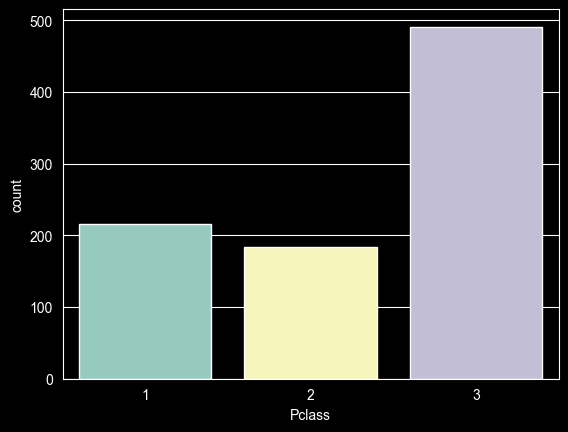

In [3]:
#sns.countplot(x='Survived', data=df, palette="Set2")
sns.countplot(x='Pclass', data=df, palette="Set3")


b.PieChart

<Axes: ylabel='count'>

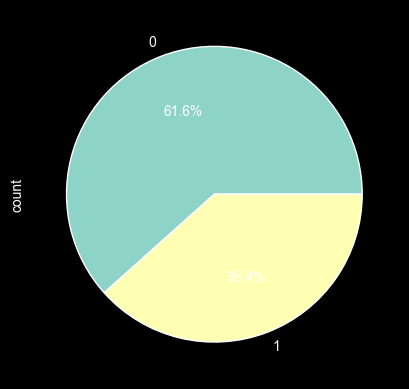

In [4]:
df["Survived"].value_counts().plot(kind="pie", autopct='%1.1f%%')


2.Numerical Data

a.Histogram

histogram is best for numerical/continuous variables (like age, salary, temperature) to visualize their distribution.

<Axes: xlabel='Age', ylabel='Count'>

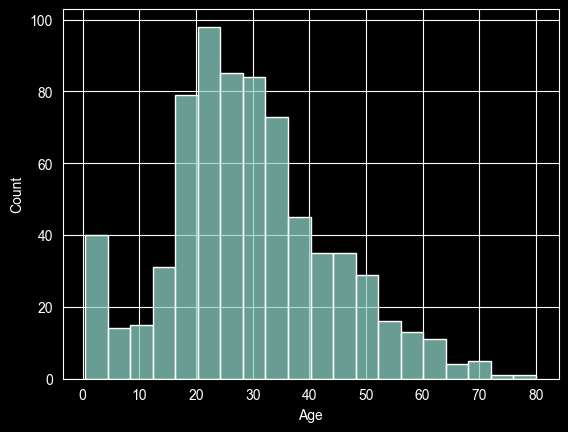

In [5]:
sns.histplot(df["Age"])

b. Distplot
Combines a histogram and an optional KDE (Kernel Density Estimate) curve in one plot.
it also tells that there is presence of skewness or not
Shows both the frequency counts and the probability density shape of the data.

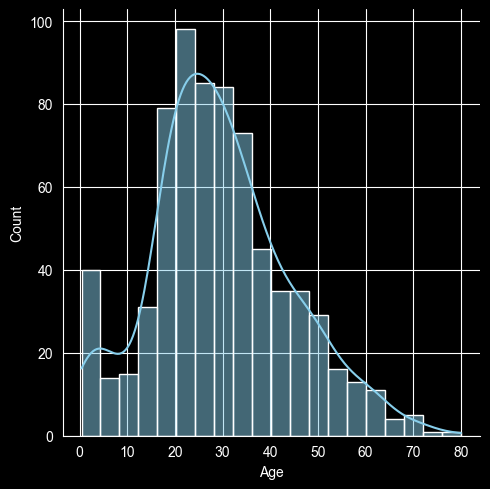

In [6]:
sns.displot(df['Age'], kde=True, bins=20, color="skyblue")

c.Boxplot
tells how many data is noicy amd outliers

<Axes: xlabel='Age'>

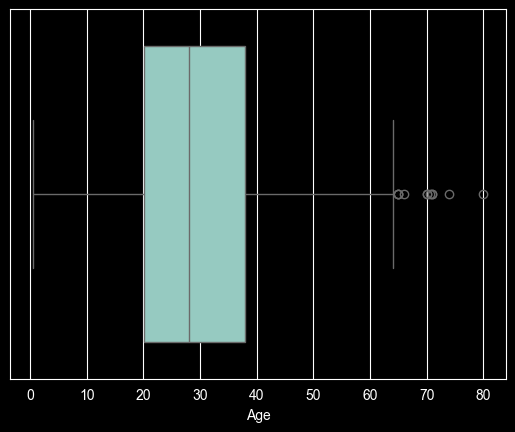

In [7]:
sns.boxplot(x="Age", data=df)
# black dots are outliers left- | is min , right- | is max blue is Most

<Axes: xlabel='Sex', ylabel='count'>

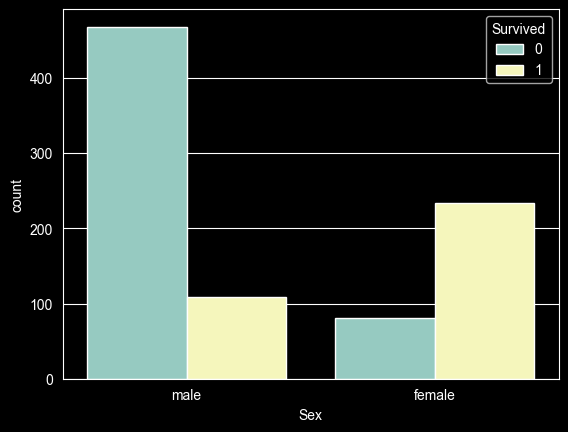

In [8]:
import seaborn as sns
sns.countplot(data=df, x='Sex', hue='Survived' )

In [9]:
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [10]:
df[df['Survived'] == 0]['Sex'].value_counts().unique()
df[df['Survived'] == 1]['Sex'].value_counts()

Sex
female    233
male      109
Name: count, dtype: int64

In [11]:
pd.pivot_table(df,
            columns=df['Sex'],
            index=df['Survived'],
            aggfunc='count',
            values='Survived',



               )

Sex,female,male
Survived,,
0,81,468
1,233,109


Bivarient or multivarient

In [12]:
df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/tips.csv')

In [13]:
df['size']

0      2
1      3
2      3
3      2
4      4
      ..
239    3
240    2
241    2
242    2
243    2
Name: size, Length: 244, dtype: int64

in bivarient there are 3 posibility of plot
num,num
num,catagori or catagori,num
catagori,catagori

<Axes: xlabel='total_bill', ylabel='tip'>

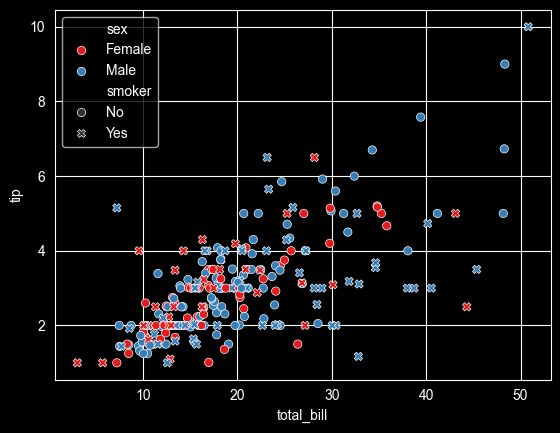

In [14]:
sns.scatterplot(data=df,x=df['total_bill'],y=df['tip'],hue=df['sex'],palette="Set1",style=df['smoker'])
# this is multivarient analysis

<Axes: xlabel='sex', ylabel='count'>

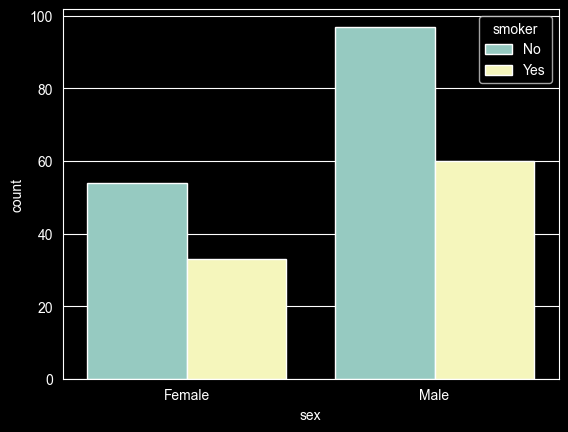

In [15]:
sns.countplot(x=df['sex'], data=df,hue=df['smoker'])

<Axes: xlabel='size', ylabel='total_bill'>

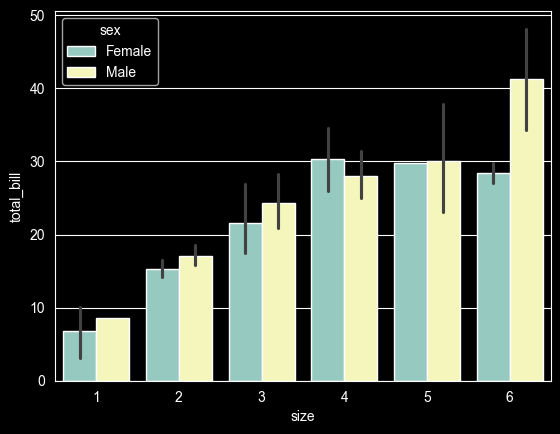

In [16]:
sns.barplot(x=df['size'], y=df['total_bill'], data=df,hue=df['sex'])

<Axes: xlabel='size', ylabel='total_bill'>

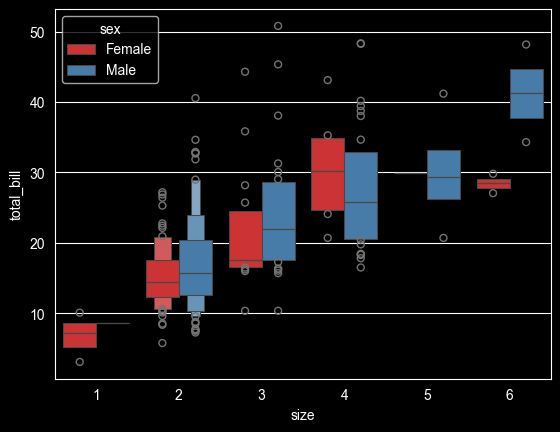

In [17]:
sns.boxenplot(data=df,x=df['size'],y=df['total_bill'],hue=df['sex'],palette="Set1")

/home/mukul/Main/Basic_DataScience-4ML/.venv/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 17.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/mukul/Main/Basic_DataScience-4ML/.venv/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 8.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


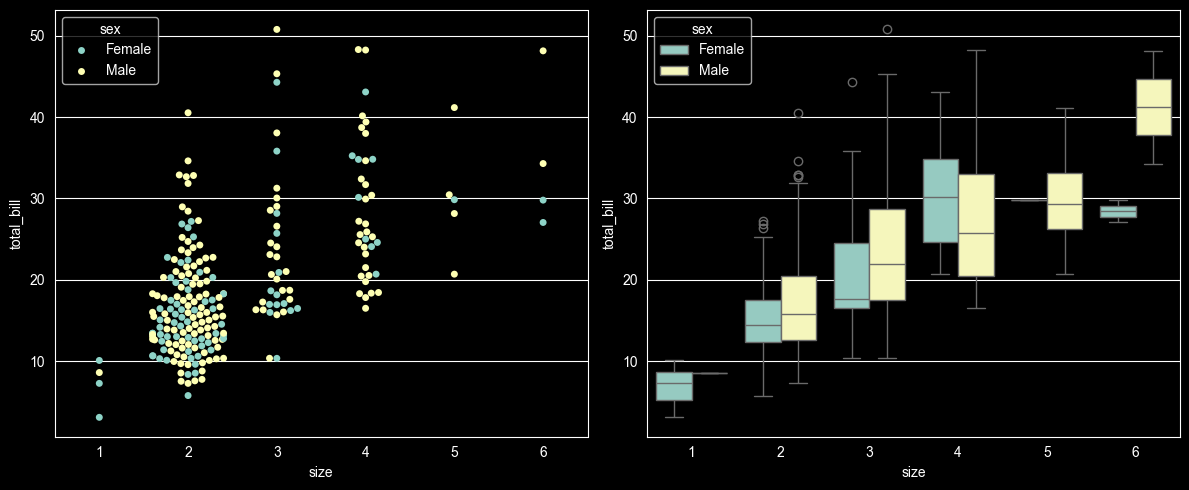

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.swarmplot(data=df, x='size', y='total_bill', hue='sex', ax=axes[0])  # String names!
sns.boxplot(data=df, x='size', y='total_bill', hue='sex', ax=axes[1])    # No dodge=True needed
plt.tight_layout()
plt.show()


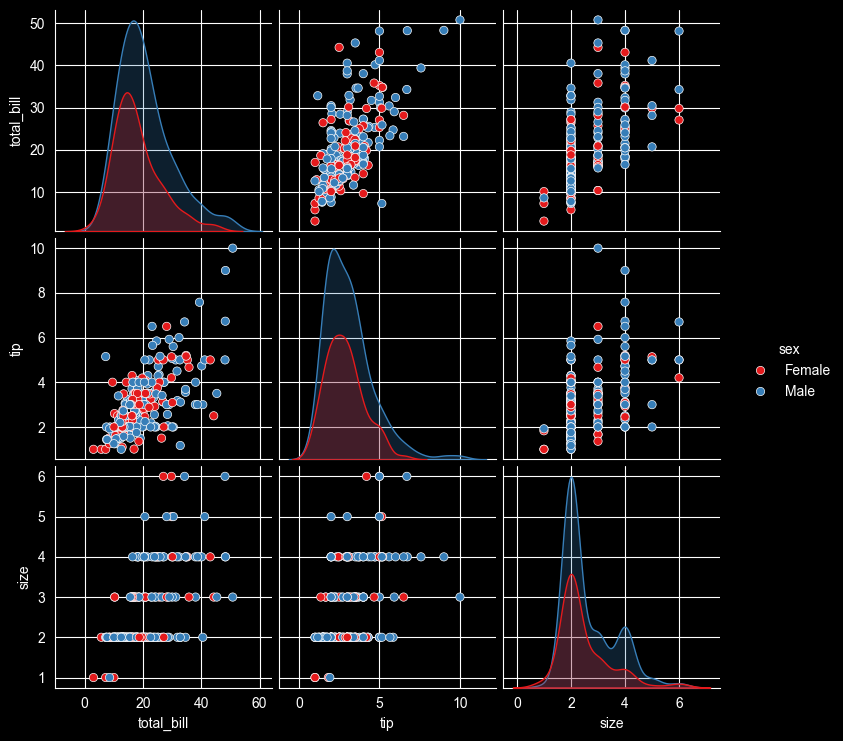

In [25]:
sns.pairplot(data=df,palette="Set1",hue='sex')